# Lab 07-02 · First-Order RC and RL Transients

Companion to chapter [07-02](../../chapters/07-02-first-order-rc-rl-transients.md). Handout: [README.md](README.md).

**How to use.** Run all cells once. Then revisit each **🔮 Predict** prompt: write your prediction *first*, then change the parameter and re-run. Every simulation here solves the circuit's differential equation **numerically**, without using the closed-form answers. The `assert` lines then check the closed-form theory against those simulations.

In [1]:
import math, shutil, subprocess, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, quad

sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style
    use_style()
except ImportError:
    pass

def simulate(f, t_end, y0, max_step=None):
    "Integrate y' = f(t, y) from 0 to t_end with tight tolerances; returns a dense solution."
    return solve_ivp(f, (0, t_end), np.atleast_1d(y0), rtol=1e-10, atol=1e-13,
                     max_step=max_step or t_end / 2000, dense_output=True)

## Part 1 — The universal step response and its landmarks

Simulate $RC\,\dot v + v = V_S$ from $v(0) = 0$ and measure the timing landmarks directly from the waveform.

tau = 1.000 ms
50% delay      : 0.6932 tau   (theory ln2 = 0.6931)
10-90% rise    : 2.1972 tau   (theory ln9 = 2.1972)
after 1 tau: 63.21% complete
after 2 tau: 86.47% complete
after 3 tau: 95.02% complete
after 4 tau: 98.17% complete
after 5 tau: 99.33% complete


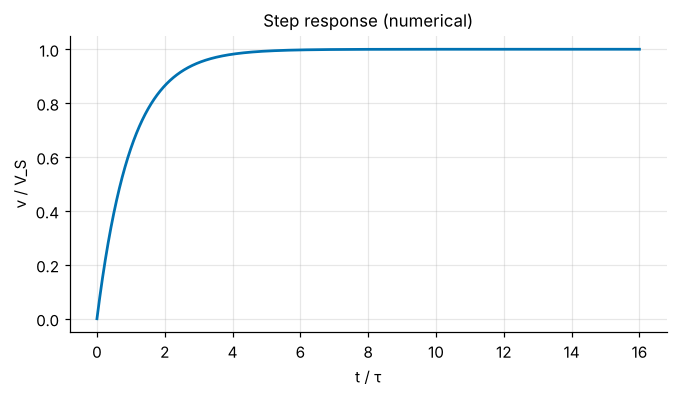

In [2]:
R, Cap, VS = 1e3, 1e-6, 1.0          # tau = 1 ms  <-- try other values
tau = R * Cap
sol = simulate(lambda t, v: (VS - v) / (R * Cap), 16 * tau, 0.0)
t = np.linspace(0, 16 * tau, 400001)
v = sol.sol(t)[0]

def first_time(level):
    return t[np.argmax(v >= level * VS)]

t50, t10, t90 = first_time(0.5), first_time(0.1), first_time(0.9)
print(f"tau = {tau*1e3:.3f} ms")
print(f"50% delay      : {t50/tau:.4f} tau   (theory ln2 = {math.log(2):.4f})")
print(f"10-90% rise    : {(t90-t10)/tau:.4f} tau   (theory ln9 = {math.log(9):.4f})")
for n in range(1, 6):
    print(f"after {n} tau: {100*sol.sol(n*tau)[0]/VS:.2f}% complete")

plt.figure(figsize=(7, 3.5))
plt.plot(t / tau, v / VS)
plt.xlabel("t / τ"); plt.ylabel("v / V_S"); plt.title("Step response (numerical)"); plt.show()

assert abs(t50 / tau - math.log(2)) < 1e-3 and abs((t90 - t10) / tau - math.log(9)) < 1e-3

**🔮 Predict.** How many time constants does it take to settle within 1 part in $2^{13}$ (12-bit accuracy, ½ LSB)? Compute $(N+1)\ln 2$ for $N = 12$, then check it with the next cell.

In [3]:
N = 12
target = 1 - 2.0 ** -(N + 1)
t_settle = t[np.argmax(v >= target * VS)]
print(f"{N}-bit settling: {t_settle/tau:.3f} tau  (theory {(N+1)*math.log(2):.3f})")
assert abs(t_settle / tau - (N + 1) * math.log(2)) < 1e-2

12-bit settling: 9.011 tau  (theory 9.011)


## Part 2 — Examples 07-02.2 and 07-02.3: switching, jumps and a changing τ

KCL at node A with the switch closed for $0 \le t < t_{open}$: $\;C\dot v = \dfrac{V_S - v}{R_1} - \dfrac{v}{R_2}$. After the switch opens, the first term disappears. No Thevenin equivalent is used here; the simulation just applies KCL.

Thevenin: V_Th = 8.000 V, R_Th = 2.000 kΩ, tau = 4.000 ms
v_C(tau) = 5.0570 V,  time to 7 V = 8.318 ms
v_C(10 ms) = 7.3433 V,  v_C(20 ms) = 1.3870 V


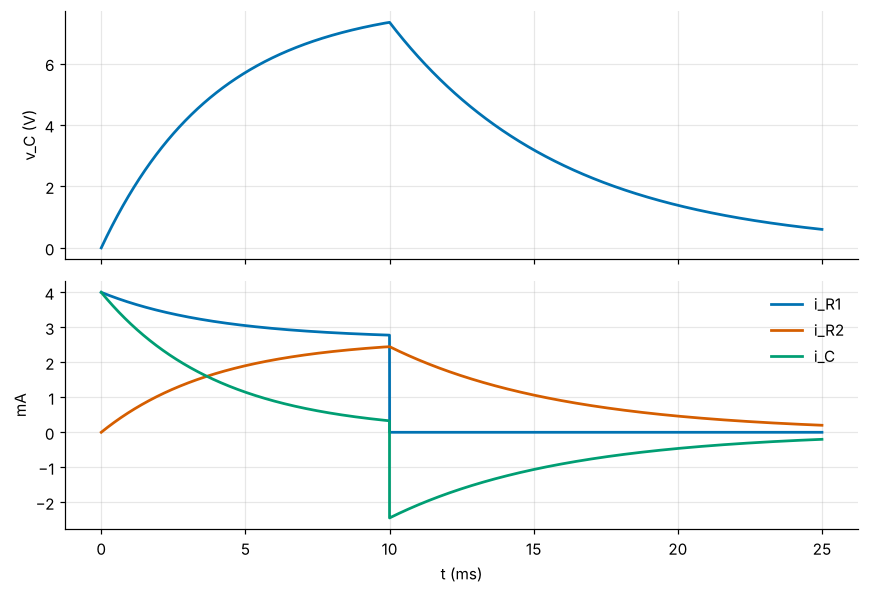

In [4]:
VS2, R1, R2, C2, t_open = 24.0, 6e3, 3e3, 2e-6, 10e-3     # <-- change R2 here
def kcl(t, y):
    i_in = (VS2 - y[0]) / R1 if t < t_open else 0.0
    return [(i_in - y[0] / R2) / C2]
sol2 = solve_ivp(kcl, (0, 25e-3), [0.0], rtol=1e-10, atol=1e-13, max_step=5e-6, dense_output=True)
t2 = np.linspace(0, 25e-3, 25001)
vc = sol2.sol(t2)[0]
iR1 = np.where(t2 < t_open, (VS2 - vc) / R1, 0.0)
iR2 = vc / R2
iC = iR1 - iR2

VTh, RTh = VS2 * R2 / (R1 + R2), R1 * R2 / (R1 + R2)
tau2 = RTh * C2
t7 = t2[np.argmax(vc >= 7)] if vc.max() >= 7 else float("nan")
print(f"Thevenin: V_Th = {VTh:.3f} V, R_Th = {RTh/1e3:.3f} kΩ, tau = {tau2*1e3:.3f} ms")
print(f"v_C(tau) = {sol2.sol(tau2)[0]:.4f} V,  time to 7 V = {t7*1e3:.3f} ms")
print(f"v_C(10 ms) = {sol2.sol(10e-3)[0]:.4f} V,  v_C(20 ms) = {sol2.sol(20e-3)[0]:.4f} V")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
a1.plot(t2 * 1e3, vc); a1.set_ylabel("v_C (V)")
a2.plot(t2 * 1e3, iR1 * 1e3, label="i_R1"); a2.plot(t2 * 1e3, iR2 * 1e3, label="i_R2"); a2.plot(t2 * 1e3, iC * 1e3, label="i_C")
a2.set_ylabel("mA"); a2.set_xlabel("t (ms)"); a2.legend(); plt.tight_layout(); plt.show()

if (R1, R2, C2, VS2) == (6e3, 3e3, 2e-6, 24.0):
    assert abs(sol2.sol(4e-3)[0] - 8 * (1 - math.exp(-1))) < 1e-5
    assert abs(t7 - 4e-3 * math.log(8)) < 2e-6

**🔮 Predict.** Change `R2` to `6e3`. Before running, compute the new $V_{Th}$, $R_{Th}$, τ and the time to reach 7 V. Also: will $v_C$ still be climbing when the switch opens at 10 ms?

## Part 3 — The ½CV² charging loss does not depend on R

Charge $C = 1$ µF to 5 V through several resistors, integrating $i^2R$ numerically. Then charge it in $N$ small steps.

In [5]:
Cq, Vq = 1e-6, 5.0
for Rq in [10.0, 1e3, 1e5]:                   # <-- predict before running!
    tq = Rq * Cq
    E, _ = quad(lambda t: (Vq / Rq) ** 2 * math.exp(-2 * t / tq) * Rq, 0, 60 * tq)
    print(f"R = {Rq:>8.0f} Ω: dissipated {E*1e6:.4f} µJ   (½CV² = {0.5*Cq*Vq**2*1e6:.4f} µJ)")
    assert abs(E - 0.5 * Cq * Vq**2) < 1e-10

def stepwise_loss(N, R=1e3):
    "Charge in N equal steps, simulating each step for 30 tau; return total resistor energy."
    tq, total, v0 = R * Cq, 0.0, 0.0
    for n in range(1, N + 1):
        Vn = Vq * n / N
        s = simulate(lambda t, y: [(Vn - y[0]) / tq, (Vn - y[0]) ** 2 / R], 30 * tq, [v0, 0.0])
        v0, total = s.y[0, -1], total + s.y[1, -1]
    return total

for N in [1, 2, 10]:
    print(f"N = {N:>2} steps: loss {stepwise_loss(N)*1e6:.4f} µJ   (theory CV²/2N = {Cq*Vq**2/(2*N)*1e6:.4f} µJ)")

R =       10 Ω: dissipated 12.5000 µJ   (½CV² = 12.5000 µJ)
R =     1000 Ω: dissipated 12.5000 µJ   (½CV² = 12.5000 µJ)
R =   100000 Ω: dissipated 12.5000 µJ   (½CV² = 12.5000 µJ)


N =  1 steps: loss 12.5000 µJ   (theory CV²/2N = 12.5000 µJ)


N =  2 steps: loss 6.2500 µJ   (theory CV²/2N = 6.2500 µJ)


N = 10 steps: loss 1.2500 µJ   (theory CV²/2N = 1.2500 µJ)


**🔮 Predict.** With $N = 10$ steps, what fraction of the single-step loss remains? In what kind of circuit could you implement a stepwise or ramped supply, and what would it cost?

## Part 4 — Square-wave drive and periodic steady state (Problem 07-02.12)

simulated: Vmax = 0.7311, Vmin = 0.2689
theory   : Vmax = 0.7311, Vmin = 0.2689


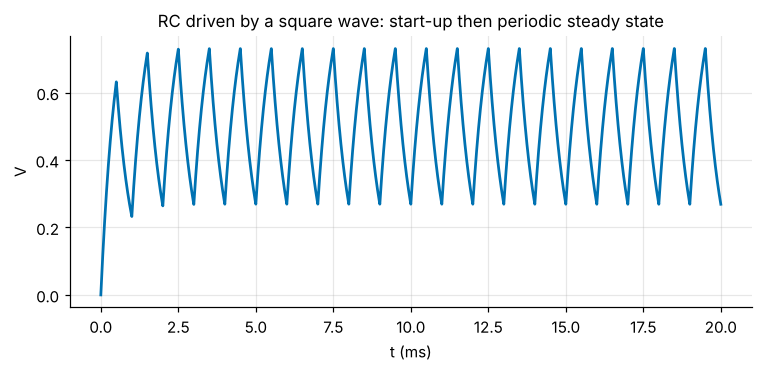

In [6]:
T, tau4 = 1e-3, 0.5e-3                         # <-- change tau4 (try 0.05e-3 and 5e-3)
sq = lambda t: 1.0 if (t % T) < T / 2 else 0.0
n_per = int(max(20, 30 * tau4 / T))
s4 = solve_ivp(lambda t, y: (sq(t) - y) / tau4, (0, n_per * T), [0.0], rtol=1e-10, atol=1e-13,
               max_step=T / 2000, dense_output=True)
tl = np.linspace((n_per - 1) * T, n_per * T, 4001)
yl = s4.sol(tl)[0]
k = math.exp(-T / (2 * tau4))
print(f"simulated: Vmax = {yl.max():.4f}, Vmin = {yl.min():.4f}")
print(f"theory   : Vmax = {1/(1+k):.4f}, Vmin = {k/(1+k):.4f}")
tt = np.linspace(0, n_per * T, 20000)
plt.figure(figsize=(8, 3.2)); plt.plot(tt * 1e3, s4.sol(tt)[0]); plt.xlabel("t (ms)"); plt.ylabel("V")
plt.title("RC driven by a square wave: start-up then periodic steady state"); plt.show()
assert abs(yl.max() - 1 / (1 + k)) < 2e-4

## Part 5 — Inductive kick: resistor versus a real diode (Example 07-02.4, Problem 07-02.14)

A relay coil ($L = 100$ mH, $R_{coil} = 200\ \Omega$, $I_0 = 60$ mA) is released at $t = 0$. We compare a 300 Ω flyback resistor with a **real exponential diode** ($I_s = 10^{-14}$ A), instead of the constant 0.7 V model used in the problem.

resistor flyback: switch sees 30.0 V; time to 10%: 0.461 ms
diode flyback   : switch sees 12.76 V; time to 10%: 0.945 ms


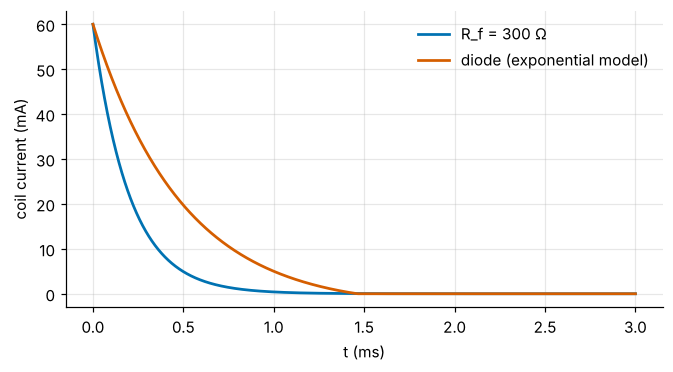

In [7]:
L5, Rc, I05 = 0.1, 200.0, 0.06
Rf = 300.0                                       # <-- try 100 and 1000 Ω
VT, Is = 0.025852, 1e-14
res = simulate(lambda t, y: [-(Rc + Rf) * y[0] / L5], 3e-3, I05, max_step=1e-6)
dio = simulate(lambda t, y: [-(Rc * y[0] + VT * math.log1p(max(y[0], 0.0) / Is)) / L5], 3e-3, I05, max_step=1e-6)
t5 = np.linspace(0, 3e-3, 3001)
i_r, i_d = res.sol(t5)[0], np.clip(dio.sol(t5)[0], 0, None)
v_sw_r = 12 + I05 * Rf
v_sw_d = 12 + VT * math.log1p(I05 / Is)
print(f"resistor flyback: switch sees {v_sw_r:.1f} V; time to 10%: {t5[np.argmax(i_r <= 0.1*I05)]*1e3:.3f} ms")
print(f"diode flyback   : switch sees {v_sw_d:.2f} V; time to 10%: {t5[np.argmax(i_d <= 0.1*I05)]*1e3:.3f} ms")
plt.figure(figsize=(7, 3.5))
plt.plot(t5 * 1e3, i_r * 1e3, label=f"R_f = {Rf:.0f} Ω"); plt.plot(t5 * 1e3, i_d * 1e3, label="diode (exponential model)")
plt.xlabel("t (ms)"); plt.ylabel("coil current (mA)"); plt.legend(); plt.show()

**🔮 Predict.** Set `Rf = 1000`. What is the switch voltage now, and how fast does the coil release? Would a 30 V transistor survive?

## Part 6 (optional) — Run the ngspice netlists from Python

If ngspice is installed, this cell runs the lab's netlists and prints their measurements. They are checked automatically against the published answers by `python tools/run_spice.py 07-02` from the repository root.

In [8]:
if shutil.which("ngspice"):
    for cir in sorted(Path(".").glob("*.cir")):
        out = subprocess.run(["ngspice", "-b", cir.name], capture_output=True, text=True).stdout
        meas = [ln.strip() for ln in out.splitlines() if "=" in ln and ln.strip()[:1].isalpha() and "e" in ln.split("=")[1][:15] and not ln.strip().startswith("Stack")]
        print(f"== {cir.name}"); print("\n".join("   " + m for m in meas[:8]))
else:
    print("ngspice not found; skipping (see SETUP.md to install it).")

== ex2_ex3_switched_rc.cir
   vc_tau              =  5.056964e+00
   t_7v                =   8.31777e-03
   ir1_0p              =  3.999666e-03
   vc_10m              =  7.343319e+00
   vc_20m              =  1.386988e+00
   ic_before           =  3.284221e-04
   ic_after            =  -2.447391e-03
== ex4_rl_kick.cir
   va_0p               =  -5.998800e+01
   il_10m              =  1.103638e+00
   vsw_0p              =  7.198800e+01
   t_10pct             =   2.30259e-02


== ex5_adc_settling.cir
   t_settle            =   2.35668e-08
== p11_integrators.cir
   vout_ideal_5m       =  4.999982e+00
   vout_leaky_10m      =  6.321173e+00


== p12_square_wave.cir
   vmax1               =  7.310586e-01 at=  1.495000e-01
   vmin1               =  2.689414e-01 at=  1.490000e-01
   vmax2               =  5.249792e-01 at=  1.495000e-01
   vmin2               =  4.750208e-01 at=  1.490000e-01
== p14_relay_flyback.cir
   t10_res             =   4.60517e-04
   t10_diode           =   9.49874e-04


---

**Done?** Answer the discussion questions in the [lab handout](README.md), then work the [problem set](../../problems/07-02-problems.md).